TEKS SIMILARITY

In [1]:
# Mengimpor pustaka standar untuk manipulasi string dan matematika
import string
import numpy as np

# Mengimpor pustaka NLTK untuk pemrosesan bahasa alami (NLP)
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.tokenize import word_tokenize

# Mengimpor Pandas untuk membaca dan memanipulasi data tabular (CSV)
import pandas as pd

# Mengimpor pustaka untuk menampilkan output tabel HTML di Jupyter Notebook
from IPython.display import HTML, display

# Mengimpor SciPy untuk menghitung jarak matematis antar teks (digunakan pada Jaccard)
from scipy.spatial.distance import cdist

# Mengimpor scikit-learn untuk mengubah teks menjadi angka (vektorisasi) dan menghitung kemiripan Cosine
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# 1. Download resource NLTK dasar
# Mengunduh 'punkt' yang berfungsi untuk memecah teks menjadi potongan-potongan kata (tokenisasi)
nltk.download('punkt')
# Paket 'punkt_tab' wajib ditambahkan agar terhindar dari error pada sistem terbaru.
nltk.download('punkt_tab')
# Mengunduh 'stopwords', yaitu daftar kata-kata umum bahasa Inggris (seperti 'and', 'the', 'is') yang akan diabaikan
nltk.download('stopwords')

# 2. Load Data (Sesuaikan path file Anda)
# Memuat data produk dari file CSV menggunakan Pandas
file_path = (
    r"C:\Users\Afardhan D S\OneDrive\Dokumen\pemdas\tugas py\pemrosesan teks\produk_oxylabs.csv"  # Contoh path
)
data = pd.read_csv(file_path)
# Mencetak total baris dari data untuk memverifikasi bahwa data telah masuk
print('Total rows : ', len(data))

# Inisialisasi PorterStemmer dan Stopwords
porter = PorterStemmer()
stop_words = set(stopwords.words('english'))


# Fungsi Preprocessing teks yang selaras
def preprocess_text(text):
  if not isinstance(text, str):
    return ''
  
  # Mengubah seluruh huruf menjadi huruf kecil (lowercase) dan menghapus semua tanda baca
  text = text.lower().translate(str.maketrans('', '', string.punctuation))
  
  # Memecah teks menjadi daftar kata terpisah (tokens)
  tokens = word_tokenize(text)
  
  cleaned = [
      # Mengembalikan kata ke bentuk dasar/akarnya menggunakan PorterStemmer (misal 'running' -> 'run')
      porter.stem(word)
      for word in tokens
      # Membuang kata jika termasuk dalam daftar stop_words atau panjangnya 2 huruf atau kurang
      if word not in stop_words and len(word) > 2
  ]
  return ' '.join(cleaned)


# Jalankan preprocessing pada kolom deskripsi (asumsi nama kolom adalah 'Deskripsi')
# Fungsi pembersihan diterapkan dan hasilnya disimpan dalam sebuah corpus (kumpulan teks bersih)
data['Deskripsi_Clean'] = data['Deskripsi'].apply(preprocess_text)
corpus = data['Deskripsi_Clean'].to_list()

# =============================================================
# A. PENCARIAN DOKUMEN MENGGUNAKAN COSINE SIMILARITY (TF-IDF)
# =============================================================
print('\n--- PENCARIAN DENGAN COSINE SIMILARITY ---')

# Buat TF-IDF vectorizer (menggunakan seluruh corpus)
# TF-IDF memberikan bobot tinggi pada kata yang sering muncul di satu dokumen tetapi jarang muncul di dokumen lain.
# Dibatasi maksimal 5000 kata unik (features).
vectorizer_tfidf = TfidfVectorizer(sublinear_tf=True, max_features=5000)
documents_tfidf_features = vectorizer_tfidf.fit_transform(corpus)

# Definisikan Query pencarian
query = 'adventure game mario'

# Transformasi query ke ruang vektor TF-IDF yang sama dengan corpus
query_tfidf_features = vectorizer_tfidf.transform([query])

# Hitung Cosine Similarities
# Menghitung sudut kemiripan antara vektor kueri dan vektor masing-masing dokumen
cosine_similarities = cosine_similarity(
    documents_tfidf_features, query_tfidf_features
)

TopK = 10
# Mengambil indeks dari 10 dokumen dengan skor tertinggi (diurutkan dari terbesar ke terkecil)
top_indices_cosine = cosine_similarities[:, 0].argsort()[::-1][:TopK]

# Kumpulkan hasil Cosine Similarity
titles_c, abstracts_c, scores_c = [], [], []
for doc_index in top_indices_cosine:
  # Asumsi kolom judul bernama 'Judul' atau 'Title', sesuaikan jika berbeda
  titles_c.append(
      data.iloc[doc_index].get('Judul', data.iloc[doc_index].get('Title', 'N/A'))
  )
  abstracts_c.append(
      data.iloc[doc_index]['Deskripsi'].replace('\n', ' ')
      if pd.notna(data.iloc[doc_index]['Deskripsi'])
      else ''
  )
  scores_c.append(cosine_similarities[doc_index, 0])

# Merangkai hasil pencarian ke dalam DataFrame Pandas dan menampilkannya sebagai tabel HTML
results_cosine = pd.DataFrame(
    {'Title': titles_c, 'Description': abstracts_c, 'Similarities': scores_c}
)
display(HTML(results_cosine.to_html()))


# =============================================================
# B. PENCARIAN DOKUMEN MENGGUNAKAN JACCARD SIMILARITY (BINARY)
# =============================================================
print('\n--- PENCARIAN DENGAN JACCARD SIMILARITY ---')

# Buat CountVectorizer biner (One-Hot Encoding) untuk korpus
# Menggunakan binary=True untuk sekadar melihat ketiadaan (0) atau kehadiran (1) suatu kata dalam dokumen
vectorizer_binarized = CountVectorizer(
    binary=True, max_features=5000, vocabulary=vectorizer_tfidf.vocabulary_
)
documents_binarized_features = vectorizer_binarized.fit_transform(
    corpus
).toarray()

# Transformasi query ke bentuk biner
query_binarized_features = vectorizer_binarized.transform([query]).toarray()

# Hitung Jaccard Similarities menggunakan SciPy cdist
# cdist menghitung Jaccard Distance (jarak/ketidakmiripan). 
# Karena yang dicari adalah kemiripan, rumusnya dibalik menjadi (1 - jarak jaccard).
jaccard_similarities = 1 - cdist(
    documents_binarized_features, query_binarized_features, metric='jaccard'
)

# Mengurutkan 10 dokumen dengan skor Jaccard tertinggi
top_indices_jaccard = jaccard_similarities[:, 0].argsort()[::-1][:TopK]

# Kumpulkan hasil Jaccard Similarity
titles_j, abstracts_j, scores_j = [], [], []
for doc_index in top_indices_jaccard:
  titles_j.append(
      data.iloc[doc_index].get('Judul', data.iloc[doc_index].get('Title', 'N/A'))
  )
  abstracts_j.append(
      data.iloc[doc_index]['Deskripsi'].replace('\n', ' ')
      if pd.notna(data.iloc[doc_index]['Deskripsi'])
      else ''
  )
  scores_j.append(jaccard_similarities[doc_index, 0])

# Merangkai hasil pencarian Jaccard ke dalam DataFrame dan menampilkannya
results_jaccard = pd.DataFrame(
    {'Title': titles_j, 'Description': abstracts_j, 'Similarities': scores_j}
)
display(HTML(results_jaccard.to_html()))

[nltk_data] Downloading package punkt to C:\Users\Afardhan D
[nltk_data]     S\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Afardhan D
[nltk_data]     S\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to C:\Users\Afardhan D
[nltk_data]     S\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


Total rows :  96

--- PENCARIAN DENGAN COSINE SIMILARITY ---


,Title,Description,Similarities
0,Super Mario 3D World,"Work together with your friends or compete for the crown in the first multiplayer 3D Mario game for the Wii U console. In the Super Mario 3D World game, players can choose to play as Mario, Luigi, Princess Peach or Toad.",0.410527
1,Super Mario Odyssey,"New Evolution of Mario Sandbox-Style Gameplay. Mario embarks on a new journey through unknown worlds, running and jumping through huge 3D worlds in the first sandbox-style Mario game since Super Mario 64 and Super Mario Sunshine. Set sail between expansive worlds aboard an airship, and perform all-new actions, such as throwing Mario's cap.",0.370458
2,Super Mario World: Super Mario Advance 2,"Mario hasn't even had a chance to savor his victory in the original Super Mario Advance, and already he's back for more in Super Mario World: Super Mario Advance 2. This game is a re-creation of the Super NES classic Super Mario World, featuring every last secret exit and all 74 levels of platform-jumping action. Once again, Princess Peach has been kidnapped by the ever-diabolical Bowser, and Mario and Luigi set out on a massive adventure to rescue her. As either Mario or Luigi, you'll solve puzzles, shoot fireballs, fly, and discover the hidden secrets in Dinosaur Island.",0.297951
3,Super Mario Advance 4: Super Mario Bros. 3,"A combination of exciting platforming action, wild power-ups, and charming Mario style has made Super Mario Bros. 3 a classic. With Super Mario Advance 4: Super Mario Bros. 3, you have your chance to partake in the special adventure anywhere you go on your Game Boy Advance. Your mission is to rescue the Mushroom Kingdom monarchs who have been transformed into animals by Bowser and his mischievous offspring, and in the process save the princess kidnapped by Bowser. Traverse eight huge worlds and encounter fun minigames and frantic boss battles as you explore the first Mario game to use an overworld map.",0.278244
4,Mario Kart Super Circuit,"Whoever hands out driver's licenses in the Mushroom Kingdom is about to be in some serious trouble. Classic Mario Kart action is back once again, this time in a colorful, lightning-fast game that you can take anywhere. Mario, Luigi, Peach, Toad, Wario, Yoshi, and Bowser are all tearing up the track, tossing Koopa Shells and laying banana peels along the way. Mario Kart: Super Circuit puts your driving skills to the test on 40 tracks, each littered with wild weapons and obstacles. Four players can compete in Mario Kart: Super Circuit using only one Game Pak. If each player has a copy of the game, bonus features and new modes of play become available.",0.241654
5,Super Mario 64,"Mario is super in a whole new way! Combining the finest 3-D graphics ever developed for a video game and an explosive sound track, Super Mario 64 becomes a new standard for video games. It's packed with bruising battles, daunting obstacle courses and underwater adventures. Retrieve the Power Stars from their hidden locations and confront your arch nemesis - Bowser, King of the Koopas!",0.237690
6,Super Mario Galaxy 2,"Super Mario Galaxy 2, the sequel to the galaxy-hopping original game, includes the gravity-defying, physics-based exploration from the first game, but is loaded with entirely new galaxies and features to challenge players. On some stages, Mario can pair up with his dinosaur buddy Yoshi and use his tongue to grab items and spit them back at enemies. Players can also have fun with new items such as a drill that lets our hero tunnel through solid rock. [Nintendo]",0.228778
7,Paper Mario,"Mario pals around in an all-new action adventure! Mario's back in his first adventure since Super Mario 64, and this time, Bowser's bent on preventing a storybook ending. When Princess Peach is kidnapped, Mario plots to rescue the seven Star Spirits and rid the Mushroom Kingdom of Koopa's cruel cohorts. As he travels from the tropical jungles of Lavalava Island to the frosty heights of Shiver Mountain, he'll 


--- PENCARIAN DENGAN JACCARD SIMILARITY ---


,Title,Description,Similarities
0,NFL 2K1,"In the end, NFL 2K1 is a deeper, more refined version of the original game.",0.111111
1,Gran Turismo 2,The world's most advanced racing game returns with thunderous new features.,0.111111
2,Super Mario 3D World,"Work together with your friends or compete for the crown in the first multiplayer 3D Mario game for the Wii U console. In the Super Mario 3D World game, players can choose to play as Mario, Luigi, Princess Peach or Toad.",0.100000
3,Super Mario Odyssey,"New Evolution of Mario Sandbox-Style Gameplay. Mario embarks on a new journey through unknown worlds, running and jumping through huge 3D worlds in the first sandbox-style Mario game since Super Mario 64 and Super Mario Sunshine. Set sail between expansive worlds aboard an airship, and perform all-new actions, such as throwing Mario's cap.",0.074074
4,NBA 2K1,"Visual Concepts has tweaked and buffed out the annoying gameplay traits that plagued its original hoops game, and the result is a highly polished product.",0.062500
5,Final Fantasy X,Final Fantasy's first game on the Playstation 2 is the first to use voice acting and a massive leap in the cinematic approach to storytelling. Stop reading and go play.,0.058824
6,Super Mario 64,"Mario is super in a whole new way! Combining the finest 3-D graphics ever developed for a video game and an explosive sound track, Super Mario 64 becomes a new standard for video games. It's packed with bruising battles, daunting obstacle courses and underwater adventures. Retrieve the Power Stars from their hidden locations and confront your arch nemesis - Bowser, King of the Koopas!",0.055556
7,Super Mario Galaxy 2,"Super Mario Galaxy 2, the sequel to the galaxy-hopping original game, includes the gravity-defying, physics-based exploration from the first game, but is loaded with entirely new galaxies and features to challenge players. On some stages, Mario can pair up with his dinosaur buddy Yoshi and use his tongue to grab items and spit them back at enemies. Players can also have fun with new items such as a drill that lets our hero tunnel through solid rock. [Nintendo]",0.051282
8,Resident Evil Code: Veronica,"Resident Evil Code: Veronica takes up the story of Claire Redfield, a character from Resident Evil 2. In that game she was searching for her brother Chris (a missing S.T.A.R.S. member) and in Resident Evil Code: Veronica we follow her to Europe where she continues her search at Umbrella headquarters.",0.045455
9,Super Mario World: Super Mario Advance 2,"Mario hasn't even had a chance to savor his victory in the original Super Mario Advance, and already he's back for more in Super Mario World: Super Mario Advance 2. This game is a re-creation of the Super NES classic Super Mario World, featuring every last secret exit and all 74 levels of platform-jumping action. Once again, Princess Peach has been kidnapped by the ever-diabolical Bowser, and Mario and Luigi set out on a massive adventure to rescue her. As either Mario or Luigi, you'll solve puzzles, shoot fireballs, fly, and discover the hidden secrets in Dinosaur Island.",0.043478


TEKS CLUSTERING

In [2]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances
from scipy.spatial.distance import pdist, squareform
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import numpy as np

# 1. FEATURE ENGINEERING & HITUNG JARAK
# ----------------------------------------------------
# TF-IDF untuk Cosine Distance
vectorizer_tfidf = TfidfVectorizer(sublinear_tf=True, max_features=5000)
X_tfidf = vectorizer_tfidf.fit_transform(corpus)

# Hitung jarak Cosine (1 - Cosine Similarity) antar dokumen
cosine_dist_matrix = cosine_distances(X_tfidf)

# Biner untuk Jaccard Distance
vectorizer_binarized = CountVectorizer(binary=True, max_features=5000)
X_binarized = vectorizer_binarized.fit_transform(corpus).toarray()

# Hitung jarak Jaccard antar dokumen
jaccard_dist_matrix = squareform(pdist(X_binarized, metric='jaccard'))


# 2. PEMODELAN CLUSTERING
# ----------------------------------------------------
# A. K-Means (Pada TF-IDF secara langsung)
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans_labels = kmeans.fit_predict(X_tfidf)

# B. Agglomerative (Pada matriks Jarak Cosine)
agglo = AgglomerativeClustering(n_clusters=4, metric='precomputed', linkage='average')
agglo_labels = agglo.fit_predict(cosine_dist_matrix)

# C. DBSCAN (Pada matriks Jarak Jaccard)
dbscan = DBSCAN(eps=0.8, min_samples=3, metric='precomputed')
dbscan_labels = dbscan.fit_predict(jaccard_dist_matrix)

# Simpan label klaster ke dalam DataFrame utama
data['KMeans_Cluster'] = kmeans_labels
data['Agglo_Cosine_Cluster'] = agglo_labels
data['DBSCAN_Jaccard_Cluster'] = dbscan_labels


# 3. EVALUASI
# ----------------------------------------------------
print("K-Means Silhouette Score:", silhouette_score(X_tfidf, kmeans_labels))
print("Agglomerative (Cosine) Silhouette Score:", silhouette_score(cosine_dist_matrix, agglo_labels, metric='precomputed'))

# Tampilkan sampel hasil
# Catatan: ganti 'Judul' dengan nama kolom yang tepat di data CSV Anda jika berbeda (misal: 'Title')
display(data[['Judul', 'KMeans_Cluster', 'Agglo_Cosine_Cluster', 'DBSCAN_Jaccard_Cluster']].head(15))

K-Means Silhouette Score: 0.004025338667522448
Agglomerative (Cosine) Silhouette Score: 0.010846495166757389


,Judul,KMeans_Cluster,Agglo_Cosine_Cluster,DBSCAN_Jaccard_Cluster
0,The Legend of Zelda: Ocarina of Time,3,0,-1
1,Super Mario Galaxy,1,0,-1
2,Super Mario Galaxy 2,1,0,-1
3,Metroid Prime,2,0,-1
4,Super Mario Odyssey,1,0,-1
5,Halo: Combat Evolved,2,0,-1
6,The House in Fata Morgana - Dreams of the Reve...,2,0,-1
7,NFL 2K1,1,0,-1
8,Uncharted 2: Among Thieves,3,0,-1
9,Tekken 3,2,0,-1


--- 1. HIERARCHICAL CLUSTERING (Agglomerative) ---

Menampilkan Dendrogram...


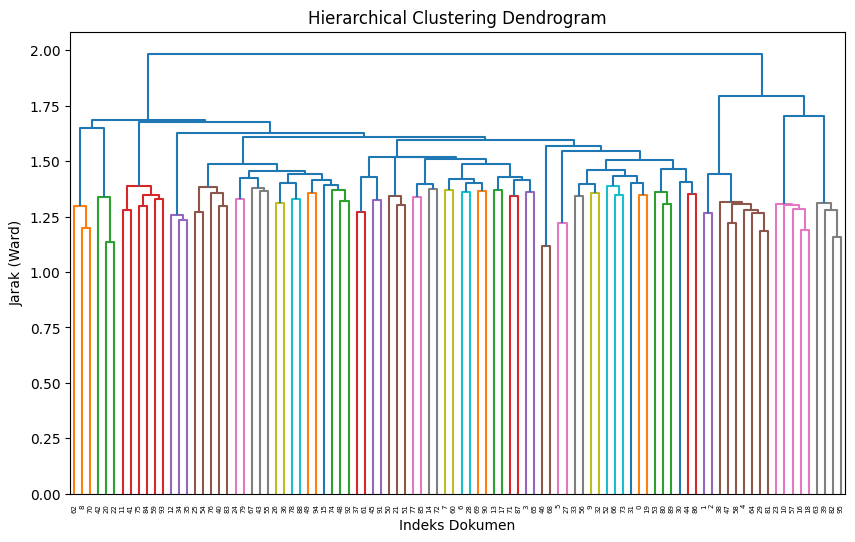


--- 2. NON-HIERARCHICAL CLUSTERING (K-Means) ---

Menampilkan Word Cloud untuk tiap klaster K-Means...

Kata dominan untuk Klaster 0:


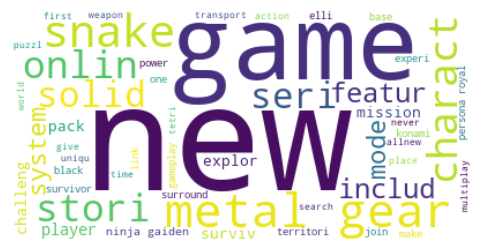


Kata dominan untuk Klaster 1:


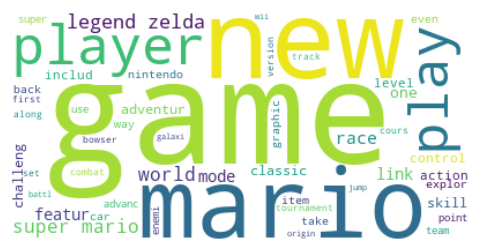


Kata dominan untuk Klaster 2:


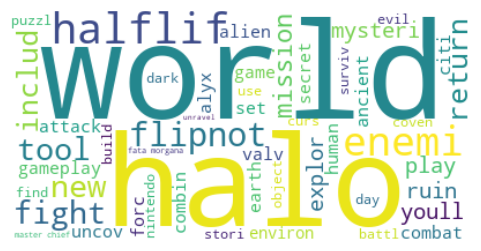


Kata dominan untuk Klaster 3:


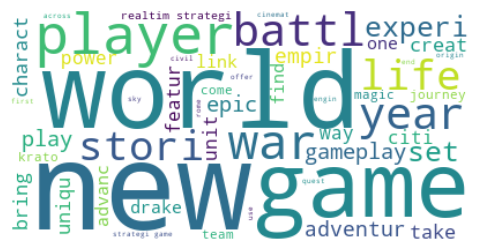


--- 3. DENSITY CLUSTERING MODEL (DBSCAN) ---
DBSCAN selesai dijalankan. (Label -1 menandakan noise/anomali)

--- EVALUASI SILHOUETTE SCORE ---
Non-Hierarchical (K-Means): 0.004025338667522448
Hierarchical (Agglomerative): 0.010846495166757389

--- SAMPEL HASIL KETIGA CLUSTERING ---


,Judul,Hierarchical_Cluster,NonHierarchical_Cluster,Density_Cluster
0,The Legend of Zelda: Ocarina of Time,0,3,-1
1,Super Mario Galaxy,0,1,-1
2,Super Mario Galaxy 2,0,1,-1
3,Metroid Prime,0,2,-1
4,Super Mario Odyssey,0,1,-1
5,Halo: Combat Evolved,0,2,-1
6,The House in Fata Morgana - Dreams of the Reve...,0,2,-1
7,NFL 2K1,0,1,-1
8,Uncharted 2: Among Thieves,0,3,-1
9,Tekken 3,0,2,-1


In [3]:
# --- IMPORT LIBRARY TAMBAHAN UNTUK CLUSTERING DAN VISUALISASI ---
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_distances
from scipy.spatial.distance import pdist, squareform
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from scipy.cluster.hierarchy import dendrogram, linkage
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Mengambil matriks fitur dari proses Text Similarity di cell atas Anda
X_tfidf = documents_tfidf_features
X_binarized = documents_binarized_features

# Menghitung matriks jarak (Distance Matrices)
cosine_dist_matrix = cosine_distances(X_tfidf)
jaccard_dist_matrix = squareform(pdist(X_binarized, metric='jaccard'))

# =====================================================================
# INDIKATOR 1: HIERARCHICAL CLUSTERING (Agglomerative)
# =====================================================================
print("--- 1. HIERARCHICAL CLUSTERING (Agglomerative) ---")
# Menggunakan matriks jarak Cosine
agglo = AgglomerativeClustering(n_clusters=4, metric='precomputed', linkage='average')
agglo_labels = agglo.fit_predict(cosine_dist_matrix)
data['Hierarchical_Cluster'] = agglo_labels

# Visualisasi Dendrogram
print("\nMenampilkan Dendrogram...")
linkage_data = linkage(X_tfidf.toarray(), method='ward', metric='euclidean')
plt.figure(figsize=(10, 6))
dendrogram(linkage_data)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Indeks Dokumen")
plt.ylabel("Jarak (Ward)")
plt.show()


# =====================================================================
# INDIKATOR 2: NON-HIERARCHICAL CLUSTERING (K-Means)
# =====================================================================
print("\n--- 2. NON-HIERARCHICAL CLUSTERING (K-Means) ---")
# K-Means diterapkan langsung pada matriks fitur TF-IDF
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans_labels = kmeans.fit_predict(X_tfidf)
data['NonHierarchical_Cluster'] = kmeans_labels

# Visualisasi Word Cloud
print("\nMenampilkan Word Cloud untuk tiap klaster K-Means...")
for c in range(4):
    print(f"\nKata dominan untuk Klaster {c}:")
    cluster_texts = data[data['NonHierarchical_Cluster'] == c]['Deskripsi_Clean'].values
    long_string = " ".join(cluster_texts)
    
    if len(long_string.strip()) > 0:
        wordcloud = WordCloud(background_color="white", max_words=50, contour_width=3).generate(long_string)
        plt.figure(figsize=(6, 3))
        plt.imshow(wordcloud, interpolation='bilinear')
        plt.axis("off")
        plt.show()
    else:
        print("Klaster kosong.")


# =====================================================================
# INDIKATOR 3: DENSITY CLUSTERING MODEL (DBSCAN)
# =====================================================================
print("\n--- 3. DENSITY CLUSTERING MODEL (DBSCAN) ---")
# DBSCAN diterapkan pada matriks jarak Jaccard
dbscan = DBSCAN(eps=0.8, min_samples=3, metric='precomputed')
dbscan_labels = dbscan.fit_predict(jaccard_dist_matrix)
data['Density_Cluster'] = dbscan_labels
print("DBSCAN selesai dijalankan. (Label -1 menandakan noise/anomali)")


# =====================================================================
# EVALUASI KESELURUHAN & HASIL DATA
# =====================================================================
print("\n--- EVALUASI SILHOUETTE SCORE ---")
print("Non-Hierarchical (K-Means):", silhouette_score(X_tfidf, kmeans_labels))
print("Hierarchical (Agglomerative):", silhouette_score(cosine_dist_matrix, agglo_labels, metric='precomputed'))

print("\n--- SAMPEL HASIL KETIGA CLUSTERING ---")
# Sesuaikan 'Judul' dengan nama kolom asli di dataset Anda jika bernama 'Title'
nama_kolom_judul = 'Judul' if 'Judul' in data.columns else 'Title'
display(data[[nama_kolom_judul, 'Hierarchical_Cluster', 'NonHierarchical_Cluster', 'Density_Cluster']].head(15))